<a href="https://colab.research.google.com/github/erikarosado/ia-y-aprendizaje-automatico/blob/main/MNA_IAyAA_Actividad_semanal_modelos_de_arboles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre:**Erika Rosado Treviño

* **Matrícula:**A00846135

https://colab.research.google.com/drive/1wUJb3bZylK1aSFX55P8sXTt3GHh14r7I?usp=sharing

# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

# **Cargando y conociendo la información**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap


RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [2]:
# Cargamos los datos y obtenemos alguna información básica:

df = pd.read_csv('fintech_default_risk.csv')

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                         0             1             2
edad                             46.000000     37.000000     48.000000
ingreso_mensual               34959.928315   8659.826698  11502.487602
antiguedad_laboral_meses        296.000000      6.000000    166.000000
score_crediticio                659.093869    728.456721    636.261824
utilizacion_credito               0.410414      0.882132      0.408709
atrasos_12m                       3.000000      1.000000      1.000000
consultas_buro_6m                 5.000000      2.000000      3.000000
num_productos                     7.000000      3.000000      1.000000
limite_credito               209105.311645  44070.504292  42132.236007
deuda_total                   77661.271706  42105.837892  15409.496357
relacion_deuda_ingreso            2.221373      4.861642      1.339550
dias_max_atraso_30d_despues       7.000000      4.000000      3.000000
clien

In [3]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"

X = df.drop(columns=[target])
y = df[target]

# **Primer hallazgo**

 De acuerdo con la tabla de las variables, el mayor atraso en los siguientes 30 días después de la evaluación es dias_max_atraso_30d_despues. Sin embargo, esta no es una variable aceptable, sino fuga de información, ya que, cuando un crédito es aprobado ese dato aún no es conocido; se observa que los clientes que tenían al menos 15 días de atraso se clasificaron como impago, mientras que los que tenían máximo 9 días no lo hicieron. Contar con esa variable de información "futura" ocasiona que el modelo siempre acierte, es por eso que es necesario corregir la información, descartando esta variable antes de realizar el entrenamiento.

In [18]:
# Primer hallazgo
print('Correlación con default_90d: %.3f' % df['dias_max_atraso_30d_despues'].corr(df[target]))
print()
print(df.groupby(target)['dias_max_atraso_30d_despues'].describe()[['count', 'min', 'max']])
print()
print('Proporción de impago por rango de días de atraso posteriores a la evaluación:')
rangos = pd.cut(df['dias_max_atraso_30d_despues'], bins=[-1, 9, 14, 89])
print(pd.crosstab(rangos, df[target], normalize='index').round(3))

Correlación con default_90d: 0.896

              count   min   max
default_90d                    
0            4414.0   0.0   9.0
1             586.0  15.0  89.0

Proporción de impago por rango de días de atraso posteriores a la evaluación:
default_90d                    0    1
dias_max_atraso_30d_despues          
(-1, 9]                      1.0  0.0
(14, 89]                     0.0  1.0


In [4]:
# Debido al desbalanceo de clases, aplicaremos una técnica de balanceo de clases.

smote = SMOTE(random_state=RANDOM_STATE   # semilla
              )

X_res, y_res = smote.fit_resample(X, y) # Balanceamos las clases con valores predeterminados de SMOTE.

X_train, X_test, y_train, y_test = train_test_split(
    X_res,
    y_res,
    test_size=0.30,  # Usemos una partición 70%-30%, pero podría ajustarse, en dado caso.
    random_state=RANDOM_STATE  # semilla
)

# **Segundo Hallazgo**

Se observan clientes que fueron inventados tomando en cuenta clientes de Train, lo que ocasiona una evaluación positiva, sin emabrgo esto se debe al uso de SMOTE por haber sido aplicado a todos los datos antes de realizar la partición. Para corregir este resultado es necesario realizar la partición antes, por medio de una estratificación. Después, también es posible balancear, siempre y cuando se aplique en los pliegues de entrenamiento.

# **Tercer Hallazgo**

Se observa una sola partición de 70-30, que no utiliza stratify y no tiene conjunto de validación ni validación cruzada. Al final, ningún dato puede ser utilizado para predecir cual será el desempeño del modelo, ya que Test evalúa el sobreentrenamiento y selecciona el mejor caso, esto ocasiona que nigún dato pueda ser utilizado después para la predicción.
Para corregir es necesario estratificar la partición y utilizar validación cruzada en el entrenamiento, mientras que Test solo se utiliza al último.

In [19]:
# Segundo hallazgo
sinteticos = X_test.index >= len(df) # SMOTE agrega los registros nuevos al final.
print('Registros en Test: %d' % len(X_test))
print('Registros sintéticos en Test: %d (%.1f%%)' % (sinteticos.sum(), 100 * sinteticos.mean()))
print('Impagos en Test: %d, de los cuales %d son sintéticos' % ((y_test == 1).sum(), ((y_test == 1) &
sinteticos).sum()))
print('Proporción de impago en Test: %.3f, contra %.3f en los datos reales' % (y_test.mean(), df[target].mean()))

Registros en Test: 2649
Registros sintéticos en Test: 1162 (43.9%)
Impagos en Test: 1322, de los cuales 1162 son sintéticos
Proporción de impago en Test: 0.499, contra 0.117 en los datos reales


# **Configuración y Entrenamiento de los Modelos**

In [5]:
# --- Modelo 1: Árbol de decisión ---
dt = DecisionTreeClassifier(random_state=RANDOM_STATE  # semilla
                            )
dt.fit(X_train, y_train)

# --- Modelo 2: Random Forest ---
rf = RandomForestClassifier(random_state=RANDOM_STATE  # semilla
                            )
rf.fit(X_train, y_train)

# --- Modelo 3: XGBoost ---
xgb = XGBClassifier(eval_metric='logloss',   # métrica caso binario
                    random_state=RANDOM_STATE  # semilla
                    )
xgb.fit(X_train, y_train)


# Obtenemos los desempeños, verificando que no estén sobreentrenados,
# ni subentrenados:
modelos = {
    "Árbol de Decisión": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}

y_probs = []   # Guardemos las probabilidades para uso posterior:
               # 0:DT, 1:RF, 2:XGBoost
print("Desempeño de los modelos:")
print("+"*25)
for nombre, modelo in modelos.items():

    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)
    y_probs.append(modelo.predict_proba(X_test)[:,1])

    # Verificando en los conjuntos de Train y Test:
    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)

    print(f"{nombre}:")

    print(f"Train: {acc_train:.4f}")
    print(f"Test: {acc_test:.4f}")
    print("+"*20)

Desempeño de los modelos:
+++++++++++++++++++++++++
Árbol de Decisión:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
Random Forest:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
XGBoost:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++


# **Cuarto Hallazgo**

Solamente un 11.7% de los clientes no paga, lo que quiere decir que si un modelo aprobara a todos, acertaría el 88.3% de las veces, pero sin identificar a ni un solo cliente de riesgo. Esto parecería algo positivo, aunque en la práctica no ayuda.
Otro problema es que la exactitud da el mismo peso a todos los errores, y en este caso no valen lo mismo: darle crédito a quien no paga cuesta 500 USD, mientras que negárselo a un buen cliente solo ocasiona la perdida de una ganancia de 100 USD.
Se sugiere utilizar las siguientes dos medidas:
AUC de la curva ROC, que muestra qué tan bien el modelo ordena a los clientes según su nivel de riesgo y AP de la curva PR, que pone la lupa en el grupo minoritario, los clientes que sí dejan de pagar.
Para decidir qué créditos aprobar hay que utilizar la utilidad esperada.

# **Quinto Hallazgo**
Los tres modelos fueron entrenados con sus hiperparámetros predeterminados, por lo que sus árboles crecen memorizando todo. En teoría fue comprobado que no hubiera sobreentrenamiento, no obstante Train y Test obtienen resultados iguales debido a la fuga del primer hallazgo y por los falsos clientes del segundo. EPor lo que la revisión no es confiable.
Eliminando la fuga, los mismos modelos sacan un AUC de 1.0 en Train, pero apenas entre 0.60 y 0.78 en validación, lo cual es un sobreentrenamiento importante.
Para corregir es necesario limitar la complejidad de los modelos con una búsqueda de hiperparámetros y comparar Train contra validación usando validación cruzada.

# **Importancia e Interpretabilidad de los Factores o Características:**

**En realidad solo debiéramos hacer el análisis de los mejores factores para el mejor modelo encotrado, pero como todos resultaron con el mejor desempeño, incluímos los tres casos a continuación como referencia.**

In [6]:
# Modelo de Árbol de Decisión (decision tree-dt):

importancias = dt.feature_importances_

# Creamos el DataFrame para ordenarlas y visualizarlas mejor:
df_importancias = pd.DataFrame({
    'Característica:': X.columns,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

print(df_importancias)

                Característica:  Importancia
11  dias_max_atraso_30d_despues          1.0
1               ingreso_mensual          0.0
2      antiguedad_laboral_meses          0.0
3              score_crediticio          0.0
0                          edad          0.0
4           utilizacion_credito          0.0
5                   atrasos_12m          0.0
7                 num_productos          0.0
6             consultas_buro_6m          0.0
8                limite_credito          0.0
9                   deuda_total          0.0
10       relacion_deuda_ingreso          0.0
12              cliente_premium          0.0


In [7]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print(importancias.head(10))

                       Variable  Importancia
11  dias_max_atraso_30d_despues     0.822857
4           utilizacion_credito     0.058264
3              score_crediticio     0.025473
10       relacion_deuda_ingreso     0.023019
6             consultas_buro_6m     0.018116
12              cliente_premium     0.011584
7                 num_productos     0.008276
9                   deuda_total     0.007900
2      antiguedad_laboral_meses     0.006443
0                          edad     0.005921


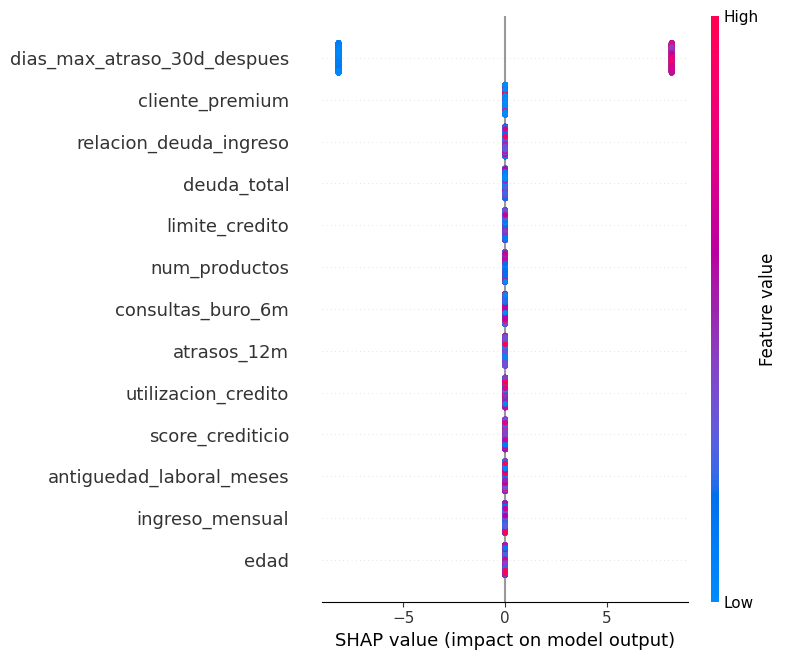

In [8]:
# Modelo XGBoost:

explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)

## **Seleccionemos y analicemos un cliente en Particular:**

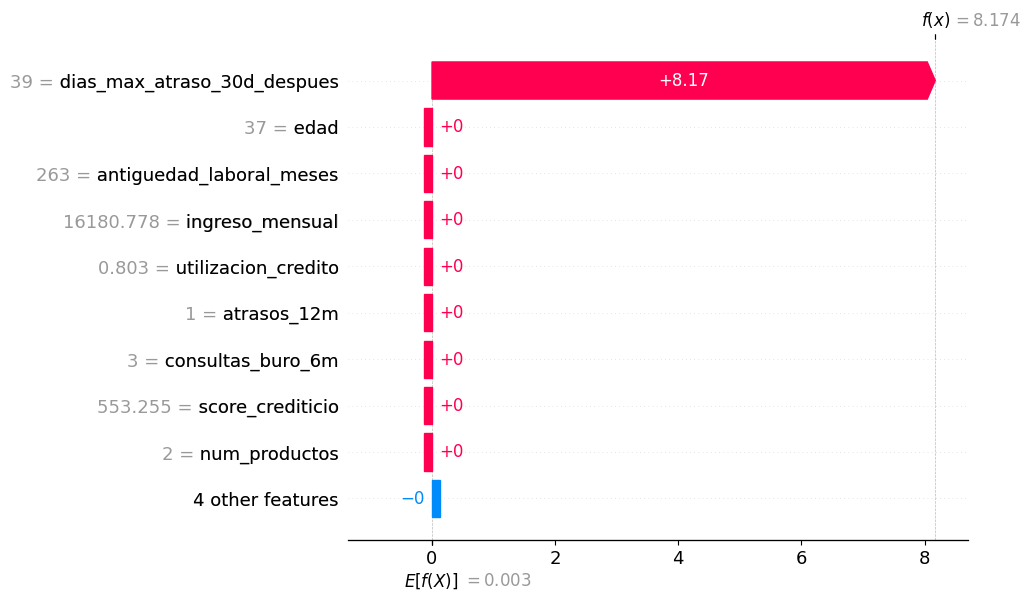

In [9]:
# Analicemos a un cliente en particular con XGBoost:

cliente = X_test.iloc[[11]]
shap_values_cliente = explainer.shap_values(cliente)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_cliente[0],
        base_values=explainer.expected_value,
        data=cliente.iloc[0],
        feature_names=cliente.columns
    )
)

**Interpretación del gráfico:**

* El factor de riesgo principal (máximo días de atraso en alguno de sus pagos durante los 30 días siguientes a la evaluación) termina siendo determinante, lo que resulta en una predicción de riesgo final (en escala log-odds) de  f(x)=8.174  (muy por encima del promedio E[f(X)]=0.003). Así, si el umbral de aprobación fuera el estándar de 0.50, este cliente sería rechazado.

# **Sexto Hallazgo**

La interpretación se basa en la fuga y en un cliente que no existe. En los tres modelos, la variable más importante es el atraso posterior, por lo que el análisis solo repite la fuga y no explica por qué la gente deja de pagar.
Además, el cliente 11 de Test que se analiza con SHAP es un registro sintético creado por SMOTE, y su explicación se basa en 39 días de atraso que aún no habían ocurrido. El texto también toma f(x) = 8.174 como si fuera el riesgo, cuando está en log-odds: en probabilidad equivale a más de 99.9% de impago.
Cabe mencionar que no es necesario expandir sobre los tres modelos, en este caso se realizó solo por sus resultados equivalentes, pero solo se debería seleccionar el mejor modelo con base en un criterio de relevancia para el negocio.


In [20]:
# Sexto hallazgo
print('Índice del cliente 11 de Test: %d (los datos reales llegan hasta el %d)' % (cliente.index[0], len(df) - 1))
print('Días de atraso posteriores a la evaluación de ese cliente: %.1f' %
cliente['dias_max_atraso_30d_despues'].iloc[0])

Índice del cliente 11 de Test: 7659 (los datos reales llegan hasta el 4999)
Días de atraso posteriores a la evaluación de ese cliente: 39.0


# **Análisis desde la perspectiva del negocio:**

In [10]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500


In [11]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += 100

            else:
                utilidad_total -= 500

    return utilidad_total



# Mejor modelo encontrado:
y_probs_mejor_modelo = y_probs[2]   # XGBoost

utilidad_05 = utilidad(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.5
)

print("Mayor Utilidad (USD) con umbral 0.5:")
print(utilidad_05)

Mayor Utilidad (USD) con umbral 0.5:
132700


Mejor umbral: 0.01
Mayor Utilidad (USD): 132700


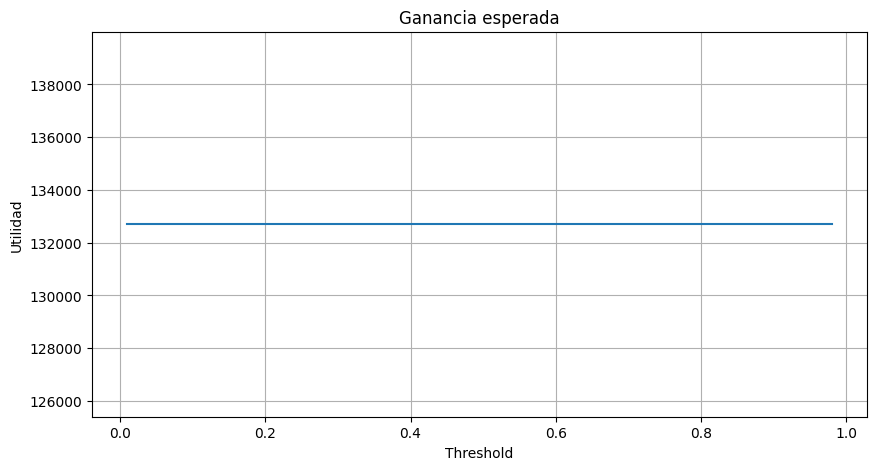

In [12]:
# Ajustando para buscar el mejor umbral óptimo:

thresholds = np.arange(
    0.01,
    0.99,
    0.01
)

utilidades = []

for th in thresholds:

    u = utilidad(
        y_test,
        y_probs_mejor_modelo,
        threshold=th
    )

    utilidades.append(u)

best_idx = np.argmax(utilidades)

best_threshold = thresholds[best_idx]

best_profit = utilidades[best_idx]

print('Mejor umbral:',best_threshold)
print('Mayor Utilidad (USD):',best_profit)



# Grafiquemos Umbral vs Utilidad:

plt.figure(figsize=(10,5))

plt.plot(
    thresholds,
    utilidades
)

plt.xlabel("Threshold")
plt.ylabel("Utilidad")
plt.title("Ganancia esperada")
plt.grid()

plt.show()

In [13]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:


def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada



In [14]:
profit_default = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.50
)

profit_optimal = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=best_threshold
)

delta = profit_optimal - profit_default

incremento_pct = (
    delta /
    abs(profit_default)
) * 100

print(f"Threshold 0.50 : ${profit_default:,.0f}")
print(f"Threshold óptimo : ${profit_optimal:,.0f}")
print(f"Diferencia : ${delta:,.0f}")
print(f"Incremento : {incremento_pct:.1f}%")

Threshold 0.50 : $500,944
Threshold óptimo : $500,944
Diferencia : $0
Incremento : 0.0%


# **Séptimo Hallazgo**

La utilidad se calcula con datos que no reflejan al negocio, fue medida en un Test con clientes sintéticos y 50% de impagos, y el umbral se eligió con esos mismos datos, por lo que el resultado sale inflado dos veces. Debido a la fuga, el modelo separa de forma muy precisa y se obtiene el mismo resultado con cualquier umbral: en el mejor caso se obtiene 0.01 con 0% de mejora.
Los 500,944 USD por cada 10,000 solicitudes suponen saber de antemano quién no pagará, y nunca se comparan contra aprobar a todos, que es el mínimo que el modelo debe superar.


## **Matriz de Confusión**



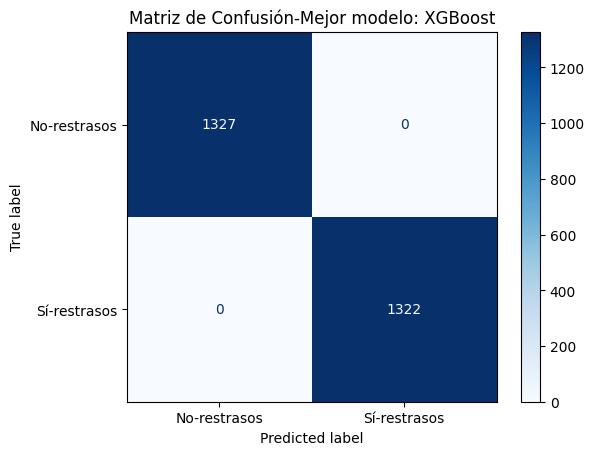

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["No-restrasos", "Sí-restrasos"]
y_pred = modelo.predict(X_test)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title(f"Matriz de Confusión-Mejor modelo: {nombre}")
plt.show()

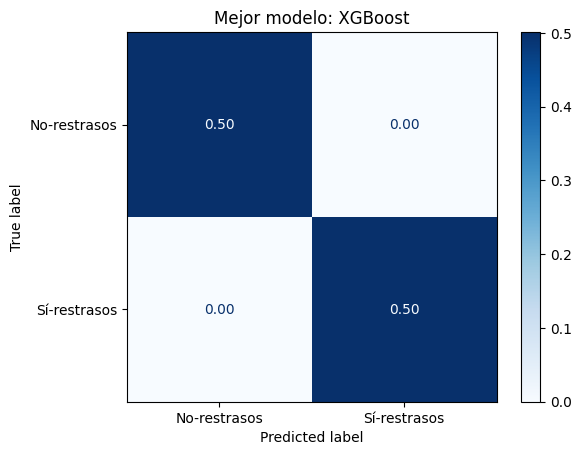

In [16]:
# O bien en su forma de proporciones:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos.
    values_format='.2f' # Total de decimales desplegadas.
)
plt.title(f"Mejor modelo: {nombre}")
plt.show()

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**

### +++++++++++ Inicia sección de Conclusiones Particulares ++++++++++++++++

# **Resultado de la auditoría del modelo de riesgo crediticio**

Recomiendo no desplegar el modelo tal como lo propuso el analista junior. Su 100% de aciertos no es real: usa el atraso máximo de los 30 días posteriores a la evaluación, un dato que solo se conoce después de aprobar el crédito, y se probó con clientes sintéticos que eran casi la mitad del Test. En producción ese dato no existe, así que el modelo tendría que decidir sin su variable principal.
Encontré 8 problemas. Los más graves: la variable del futuro, los clientes sintéticos en la prueba, que todas las decisiones se tomaron con los mismos datos de prueba y que se juzgó por exactitud, una métrica engañosa porque aprobar a todos ya da 88%.
Corregí la propuesta y el resultado sigue siendo bueno, aunque más modesto. Recomiendo XGBoost con árboles sencillos y un umbral de 0.17 (rechazar a quien tenga más de 17% de probabilidad de impago). Por cada 10,000 solicitudes, medidas con clientes que el modelo nunca vio, aprobar a todos sin modelo deja una utilidad de 296,000 USD. Con el umbral estándar de 0.5 se aprueba el 97% de las solicitudes y la utilidad sube a 366,667 USD. Con el umbral de 0.17 se aprueba el 80% y la utilidad llega a 536,000 USD, es decir, unos 240,000 USD más que aprobar a todos y 169,000 más que con el umbral estándar. A cambio, se rechaza a 1 de cada 5 solicitantes, incluidos algunos buenos clientes, y aún se escapan cerca de 4 de cada 10 impagos.
Para llevarlo a producción recomiendo:
* Quitar la variable de atraso posterior y confirmar con quienes armaron la base que ninguna otra columna se calcule después de la evaluación.
* Correr el modelo 1 o 2 meses en paralelo, sin que decida, y comparar sus predicciones con lo que pase realmente.
* Usar el umbral de 0.17 y recalcularlo si cambian la ganancia por cliente o la pérdida por impago.
* Que un analista revise los casos cercanos al umbral en lugar de rechazarlos automáticamente.
* Medir cada mes el AUC, la tasa de impago de los aprobados y la utilidad, y reentrenar si bajan.
* Pedir a Cumplimiento que valide las variables usadas. Hoy el modelo no usa la edad, y conviene mantenerlo así.

Con estos cambios, el modelo sí puede ir a producción, de forma gradual y supervisada.



### +++++++++++ Termina sección de conclusiones particulares ++++++++++++++

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

Se encontraron dos principales erroresen el modelo: una variable con información del futuro y un conjunto de prueba lleno de clientes sintéticos. Cualquiera bastaba para inflar los resultados. Las lecciones fueron verificar cuándo se conoce cada variable antes de entrenar, dividir los datos antes de transformarlos y reservar el Test para el final. También se vio que equilibrar las clases no siempre ayuda: SMOTE empeoró los tres modelos, mientras que fijar el umbral según los costos del negocio dio mejores resultados. Además, los árboles se sobreentrenan si no se limita su complejidad, y el mejor modelo fue el más sencillo, un XGBoost con árboles de un solo nivel.
Se usó un asistente de IA (LLM) como apoyo para generar una primera lista de errores comunes, agilizar el código de validación cruzada, la búsqueda de hiperparámetros y las gráficas SHAP, y ordenar el reporte. Las decisiones clave fueron del autor: detectar la fuga exigió leer la tabla de variables y analizar cuándo se obtiene cada dato, y derivar el umbral de la utilidad, comprobado con el cálculo de 1/6, fue criterio propio. Como el LLM puede entregar código que corre sin errores pero repite fallas como aplicar SMOTE antes de dividir los datos, el autor revisó cada paso y contrastó cada cifra del reporte con el cuaderno.


### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Modelos de Árboles >>>**